# Datos sintéticos · probar métricas con ruido conocido

[Explicación completa y diagramas](README.md) · [Mapa de estudio](../README.md)

Notebook autocontenido: se ejecuta de arriba hacia abajo y no importa funciones de `code/`. Las ecuaciones se implementan aquí para poder leerlas. Las salidas guardadas muestran simulación del modelo rígido nominal; no son mediciones del prototipo.

**Convenciones:** base fija, metros, radianes y vectores columna. Las longitudes se toman de la tabla 2 de Ramzy et al. (2024); los métodos siguen las semanas 4–9 del curso. [Fuentes y alcance](../../docs/paper.md).

## 1. Para qué sirve este caso auxiliar

Se conoce una posición ideal generada por el modelo. Se suma ruido artificial para comprobar lectura, cálculo de errores y visualización. El resultado permite verificar el procesamiento; no demuestra precisión de hardware ni reproduce mediciones de los autores.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
l1, l2, l3 = 0.04, 0.29, 0.24  # metros, tabla 2 del paper

def position(q):
    q1, q2, q3 = q
    rho = l2 * np.cos(q2) + l3 * np.cos(q2 + q3)
    height = l2 * np.sin(q2) + l3 * np.sin(q2 + q3)
    return np.array([np.cos(q1) * rho, np.sin(q1) * rho, l1 + height])

rng = np.random.default_rng(2026)
samples = 500
noise_std = 0.002  # metros por eje
angles = rng.uniform(-1, 1, size=(samples, 3))
truth = np.array([position(q) for q in angles])
noise = rng.normal(0, noise_std, size=truth.shape)
observations = truth + noise

## 2. De errores por eje a RMSE cartesiano

Se calcula $e_i=y_i-p_i$. Cada observación tiene tres componentes independientes con desviación estándar $\sigma$.

$$\mathrm{RMSE}=\sqrt{\frac1N\sum_i\|e_i\|^2},\qquad\mathbb E[\|e_i\|^2]=3\sigma^2.$$

La escala de referencia es $\sqrt{3}\sigma$. No es el valor exacto de cada muestra finita ni una identidad para la esperanza del RMSE. La semilla permite repetir el mismo experimento.

RMSE observado (m): 0.003504551276870022
Escala esperada (m): 0.0034641016151377543


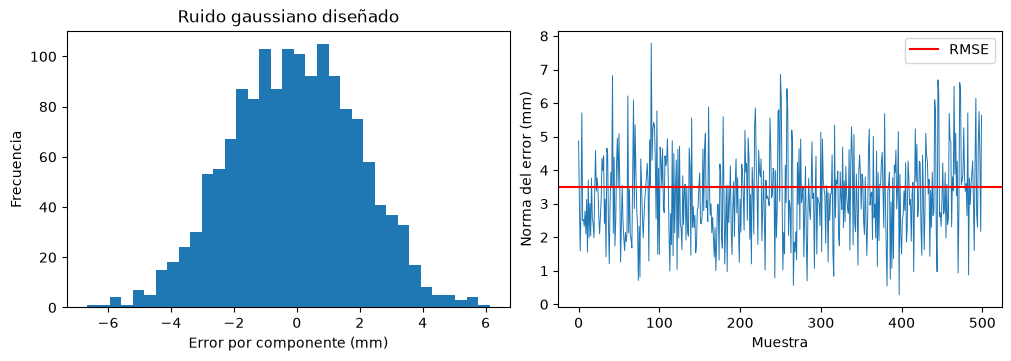

In [2]:
errors = observations - truth
error_norms = np.linalg.norm(errors, axis=1)
rmse = np.sqrt(np.mean(error_norms**2))
reference_scale = np.sqrt(3) * noise_std
print("RMSE observado (m):", rmse)
print("Escala esperada (m):", reference_scale)
assert 0.85 * reference_scale < rmse < 1.15 * reference_scale

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].hist(errors.ravel() * 1000, bins=35)
axes[0].set(xlabel="Error por componente (mm)", ylabel="Frecuencia", title="Ruido gaussiano diseñado")
axes[1].plot(error_norms * 1000, linewidth=0.7)
axes[1].axhline(rmse * 1000, color="red", label="RMSE")
axes[1].set(xlabel="Muestra", ylabel="Norma del error (mm)")
axes[1].legend()
plt.show()

## Lectura y ejercicio

Con esta semilla, el RMSE es aproximadamente 0.003505 m. La tolerancia del 15% sirve para comprobar este generador; no es un requisito de desempeño del VSL. Al duplicar la desviación del ruido, la escala del RMSE también se duplica.

Cambiar semilla debe cambiar las muestras y mantener una escala semejante. Los notebooks principales usan el modelo ideal sin este ruido; no se ha inyectado automáticamente en el controlador. [Volver al mapa de estudio](../README.md).